In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image




In [6]:

df = pd.read_csv("fashion_products_selected_v2.csv")

print("Dataset shape:", df.shape)

Dataset shape: (18632, 17)


In [7]:
# verify selected category
print("Gender distribution:")
display(df["gender"].value_counts())

print("\nArticle type count:")
print(df["articleTypeName"].nunique())

print("\nSub-category count:")
print(df["subCategoryName"].nunique())


Gender distribution:


gender
Women    18632
Name: count, dtype: int64


Article type count:
112

Sub-category count:
37


In [8]:
# examine classification labels
article_counts = (
    df["articleTypeName"]
    .value_counts()
    .reset_index()
)

article_counts.columns = [
    "Article Type",
    "Image Count"
]

display(article_counts)

,Article Type,Image Count
0,Kurtas,1761
1,Handbags,1689
2,Tops,1532
3,Heels,1322
4,Tshirts,1116
...,...,...
107,Innerwear Vests,1
108,Tracksuits,1
109,Ipad,1
110,Hair Accessory,1


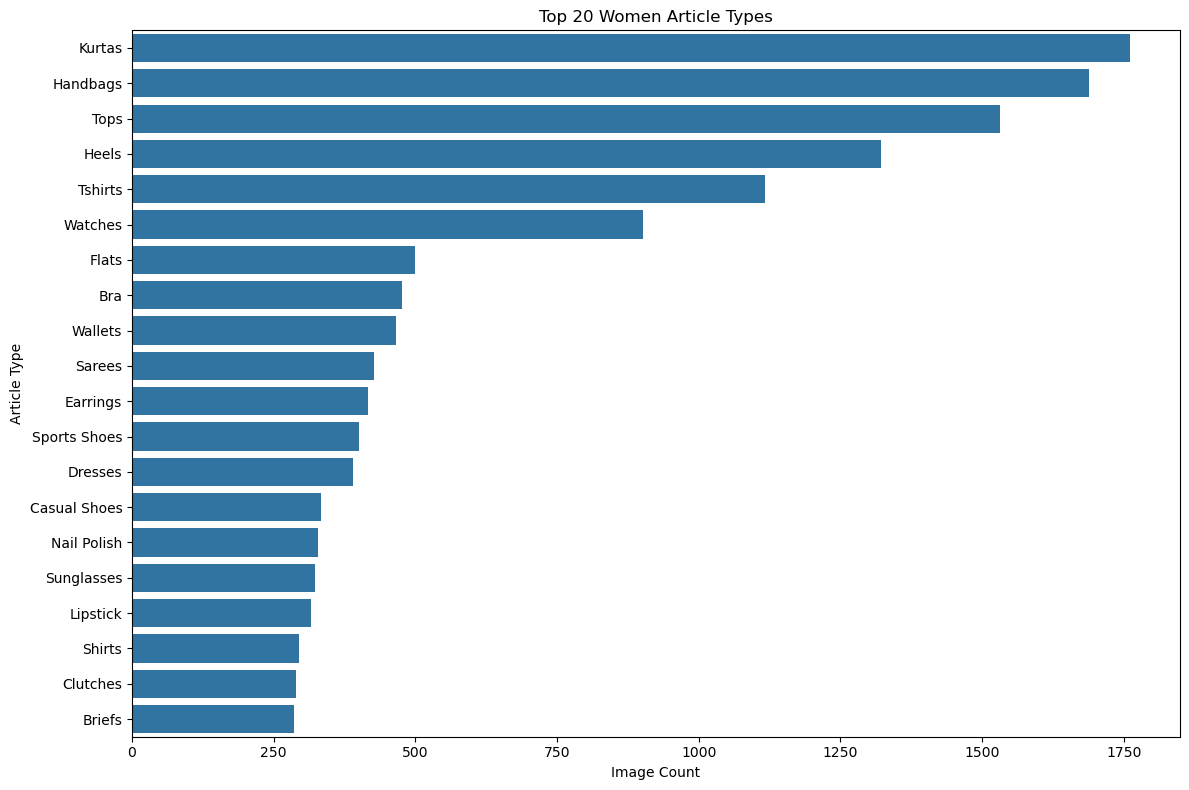

In [9]:
# Visualize class distribution
plt.figure(figsize=(12, 8))

top_articles = (
    df["articleTypeName"]
    .value_counts()
    .head(20)
)

sns.barplot(
    x=top_articles.values,
    y=top_articles.index
)

plt.title("Top 20 Women Article Types")
plt.xlabel("Image Count")
plt.ylabel("Article Type")
plt.tight_layout()
plt.show()

<!-- Image Label Analysis -->

The `articleTypeName` field is selected as the classification target because it provides specific product-level labels within the selected Women category.

The dataset contains a large number of article types, but their image counts are not necessarily balanced. Therefore, class distribution will be evaluated before constructing the final image-classification dataset.

<!-- Image Download -->

In [10]:
# Create image directory
image_dir = "images"

os.makedirs(image_dir, exist_ok=True)

print("Image directory:", image_dir)


Image directory: images


In [11]:
# Download images--->use the URL stored in imageURL---->tc
import requests
from io import BytesIO

downloaded = 0
failed = 0

for _, row in df.iterrows():

    image_path = os.path.join(
        image_dir,
        row["filename"]
    )

    if os.path.exists(image_path):
        downloaded += 1
        continue

    try:
        response = requests.get(
            row["imageURL"],
            timeout=10
        )

        response.raise_for_status()

        with open(image_path, "wb") as f:
            f.write(response.content)

        downloaded += 1

    except Exception as e:
        failed += 1

print("Images available:", downloaded)
print("Download failures:", failed)

Images available: 18630
Download failures: 2


In [12]:
# Image validation
valid_images = []
invalid_images = []

for _, row in df.iterrows():

    image_path = os.path.join(
        image_dir,
        row["filename"]
    )

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images.append(row["filename"])

    except Exception:
        invalid_images.append(row["filename"])

print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))

Valid images: 18630
Invalid images: 2


In [13]:
# retain only valid images
df_images = df[
    df["filename"].isin(valid_images)
].copy()

print("Dataset after image validation:", df_images.shape)

Dataset after image validation: (18630, 17)


<!-- Resize + Normalize -->

In [14]:
# Resize Image
IMG_SIZE = (224, 224)

def preprocess_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [15]:
df_images["articleTypeName"].value_counts()

articleTypeName
Kurtas             1761
Handbags           1688
Tops               1532
Heels              1322
Tshirts            1116
                   ... 
Innerwear Vests       1
Tracksuits            1
Ipad                  1
Hair Accessory        1
Tablet Sleeve         1
Name: count, Length: 112, dtype: int64

In [17]:
class_counts = (
    df_images["articleTypeName"]
    .value_counts()
    .sort_values()
)

display(class_counts.head(30))

articleTypeName
Innerwear Vests              1
Ipad                         1
Hair Accessory               1
Tracksuits                   1
Tablet Sleeve                1
Blazers                      2
Lehenga Choli                2
Ties and Cufflinks           2
Face Serum and Gel           2
Lounge Tshirts               3
Travel Accessory             4
Sandals                      4
Makeup Remover               4
Beauty Accessory             4
Lip Plumper                  4
Robe                         4
Toner                        5
Waistcoat                    5
Face Scrub and Exfoliator    5
Body Lotion                  6
Umbrellas                    6
Eye Cream                    6
Shrug                        6
Nail Essentials              6
Salwar and Dupatta           7
Duffel Bag                   7
Tights                       8
Mufflers                     8
Lounge Shorts                9
Shapewear                    9
Name: count, dtype: int64

In [18]:
print("Total classes:", len(class_counts))

print("\nClasses with fewer than 10 images:")
display(class_counts[class_counts < 10])

print("\nClasses with fewer than 20 images:")
display(class_counts[class_counts < 20])

print("\nClasses with fewer than 50 images:")
display(class_counts[class_counts < 50])

Total classes: 112

Classes with fewer than 10 images:


articleTypeName
Innerwear Vests              1
Ipad                         1
Hair Accessory               1
Tracksuits                   1
Tablet Sleeve                1
Blazers                      2
Lehenga Choli                2
Ties and Cufflinks           2
Face Serum and Gel           2
Lounge Tshirts               3
Travel Accessory             4
Sandals                      4
Makeup Remover               4
Beauty Accessory             4
Lip Plumper                  4
Robe                         4
Toner                        5
Waistcoat                    5
Face Scrub and Exfoliator    5
Body Lotion                  6
Umbrellas                    6
Eye Cream                    6
Shrug                        6
Nail Essentials              6
Salwar and Dupatta           7
Duffel Bag                   7
Tights                       8
Mufflers                     8
Lounge Shorts                9
Shapewear                    9
Name: count, dtype: int64


Classes with fewer than 20 images:


articleTypeName
Innerwear Vests               1
Ipad                          1
Hair Accessory                1
Tracksuits                    1
Tablet Sleeve                 1
Blazers                       2
Lehenga Choli                 2
Ties and Cufflinks            2
Face Serum and Gel            2
Lounge Tshirts                3
Travel Accessory              4
Sandals                       4
Makeup Remover                4
Beauty Accessory              4
Lip Plumper                   4
Robe                          4
Toner                         5
Waistcoat                     5
Face Scrub and Exfoliator     5
Body Lotion                   6
Umbrellas                     6
Eye Cream                     6
Shrug                         6
Nail Essentials               6
Salwar and Dupatta            7
Duffel Bag                    7
Tights                        8
Mufflers                      8
Lounge Shorts                 9
Shapewear                     9
Laptop Bag              


Classes with fewer than 50 images:


articleTypeName
Innerwear Vests               1
Ipad                          1
Hair Accessory                1
Tracksuits                    1
Tablet Sleeve                 1
Blazers                       2
Lehenga Choli                 2
Ties and Cufflinks            2
Face Serum and Gel            2
Lounge Tshirts                3
Travel Accessory              4
Sandals                       4
Makeup Remover                4
Beauty Accessory              4
Lip Plumper                   4
Robe                          4
Toner                         5
Waistcoat                     5
Face Scrub and Exfoliator     5
Body Lotion                   6
Umbrellas                     6
Eye Cream                     6
Shrug                         6
Nail Essentials               6
Salwar and Dupatta            7
Duffel Bag                    7
Tights                        8
Mufflers                      8
Lounge Shorts                 9
Shapewear                     9
Laptop Bag              

In [ ]:
MIN_IMAGES = 50
valid_classes = class_counts[
    class_counts >= MIN_IMAGES
].index

df_model = df_images[
    df_images["articleTypeName"].isin(valid_classes)
].copy()

print("Original dataset:", df_images.shape)
print("Filtered modeling dataset:", df_model.shape)
print("Number of classes:", df_model["articleTypeName"].nunique())

Original dataset: (18630, 17)
Filtered modeling dataset: (17750, 17)
Number of classes: 54


In [21]:
model_class_counts = (
    df_model["articleTypeName"]
    .value_counts()
    .sort_values()
)

display(model_class_counts)

articleTypeName
Bracelet                   50
Highlighter and Blush      53
Jackets                    56
Jewellery Set              58
Sweatshirts                59
Face Moisturisers          61
Shorts                     70
Bangle                     71
Scarves                    72
Foundation and Primer      76
Night suits                78
Socks                      79
Track Pants                85
Stoles                     87
Sweaters                   88
Kurta Sets                 90
Ring                       92
Trousers                   95
Kajal and Eyeliner        102
Skirts                    104
Dupatta                   116
Deodorant                 129
Capris                    129
Lip Gloss                 144
Leggings                  153
Necklace and Chains       160
Pendant                   168
Nightdress                189
Tunics                    228
Jeans                     228
Kurtis                    232
Flip Flops                247
Belts                   

In [26]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_model,
    test_size=0.30,
    stratify=df_model["articleTypeName"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["articleTypeName"],
    random_state=42
)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (12425, 17)
Validation: (2662, 17)
Test: (2663, 17)


"When you split the data, preserve the distribution of every article-type class across train, validation and test."

In [27]:
print("Training classes:", train_df["articleTypeName"].nunique())
print("Validation classes:", val_df["articleTypeName"].nunique())
print("Test classes:", test_df["articleTypeName"].nunique())

Training classes: 54
Validation classes: 54
Test classes: 54


18,632 Women products
        ↓
Remove rare article types (< 50 images)
        ↓
17,750 images
        ↓
54 article-type classes

In [28]:
# Save the three split CSV
train_df.to_csv("train_images_v2.csv", index=False)
val_df.to_csv("val_images_v2.csv", index=False)
test_df.to_csv("test_images_v2.csv", index=False)
print("Train, validation and test splits saved successfully.")


Train, validation and test splits saved successfully.


In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Load the saved training split
train_df = pd.read_csv("train_images_v2.csv") #<---------

# Recreate label encoder
label_encoder = LabelEncoder()

label_encoder.fit(train_df["articleTypeName"])

print("Number of classes:", len(label_encoder.classes_))

Number of classes: 54


In [ ]:
# create mapping
label_mapping = pd.DataFrame({
    "label": range(len(label_encoder.classes_)),
    "articleTypeName": label_encoder.classes_
})


display(
    label_mapping.style.hide(axis="index")
)



label,articleTypeName
0,Bangle
1,Belts
2,Bra
3,Bracelet
4,Briefs
5,Capris
6,Casual Shoes
7,Clutches
8,Deodorant
9,Dresses


In [ ]:
# save mapping-------------->
label_mapping.to_csv(
    "article_type_label_mapping_v2.csv", #<-------------
    index=False
)

print("Label mapping saved successfully.")

Label mapping saved successfully.


In [ ]:
# verify
print("Number of classes:", len(label_mapping))
print("Unique labels:", label_mapping["label"].nunique())

display(label_mapping.head(10))

Number of classes: 54
Unique labels: 54


,label,articleTypeName
0,0,Bangle
1,1,Belts
2,2,Bra
3,3,Bracelet
4,4,Briefs
5,5,Capris
6,6,Casual Shoes
7,7,Clutches
8,8,Deodorant
9,9,Dresses
